# Лабораторная работа 5. Регрессия

|  |  |
|---|---|
| Дисциплина | Машинное обучение |
| Студент | Масенькин Максим |
| Группа | ПИбд-41 |
| Вариант | 20 |

## Задание

Использовать регрессию по варианту для своих данных, самостоятельно сформулировав задачу. Оценить,
насколько хорошо она подходит для решения сформулированной задачи.

| Пункт задания | Вариант 20 |
|---|---|
| Тип регрессии | линейная регрессия (20 % 5 = 0) |
| Данные | сделки инсайдеров Tesla, 156 записей |
| Задача | предсказать сумму сделки по типу сделки, должности инсайдера, числу акций и дате |
| Модель | `LinearRegression` в конвейере с `OneHotEncoder` и `StandardScaler` |
| Пособие | «Теория и практика машинного обучения»: регрессионный анализ, метод наименьших квадратов, $R^2$ и анализ остатков — стр. 57–61; one-hot кодирование — стр. 193–194, листинг 26 |

## Ход работы

1. Загрузить данные о сделках и подготовить признаки.
2. Обучить линейную регрессию на 75% сделок.
3. Оценить качество модели на отложенной выборке и кросс-валидацией.
4. Проверить остатки модели и объяснить её веса.
5. Оценить, насколько линейная регрессия подходит для задачи.
6. Показать, почему цена акции не входит в признаки.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict, train_test_split

from mllab import RANDOM_STATE
from mllab.datasets import load_tesla
from mllab.metrics import regression_report
from mllab.preprocessing import build_pipeline, calendar_features
from mllab.reporting import make_table


CATEGORICAL = ["transaction", "relationship"]
NUMERIC = ["log_shares", "month", "year"]
TEST_SIZE = 0.25
FOLDS = 10
GROUPS = {
    "продажа": ("#2a78d6", "o"),
    "платное исполнение опциона": ("#eb6834", "s"),
    "нулевая сделка": ("#1baf7a", "D"),
}

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.width", 120)

## 1. Данные и признаки

Набор содержит 156 сделок семи инсайдеров Tesla с ноября 2021 по декабрь 2022: продажи акций и
исполнения опционов, т. е. покупки акций по заранее оговорённой цене.

Задача работы — предсказать сумму сделки по её типу, должности инсайдера, числу акций и дате.
Сумма — число, поэтому это задача регрессии. Во второй части ЛР 3 сумму предсказывало дерево
решений по типу сделки и месяцу, и оно объяснило только половину разброса логарифма суммы: в
задаче не было должности инсайдера и числа акций, здесь эти признаки добавлены.

При загрузке набор приведён к удобному виду:

- имена столбцов переведены в snake_case;
- числа с разделителями тысяч вида `"2,056,775"` преобразованы в целые;
- даты разобраны из строк.

In [2]:
tesla = load_tesla()
value = tesla["value"]
zero = value == 0
X_tesla = pd.concat(
    [
        tesla[CATEGORICAL],
        np.log1p(tesla["shares"]).rename("log_shares"),
        calendar_features(tesla["date"], ("month", "year")),
    ],
    axis=1,
)
group = pd.Series(
    np.select(
        [zero, tesla["transaction"] == "Sale"],
        ["нулевая сделка", "продажа"],
        "платное исполнение опциона",
    ),
    index=tesla.index,
)
sales = int((group == "продажа").sum())

make_table(
    {
        "сделок": len(tesla),
        "период": f"{tesla['date'].min():%d.%m.%Y} – {tesla['date'].max():%d.%m.%Y}",
        "продаж / исполнений опционов": f"{sales} / {len(tesla) - sales}",
        "из них с нулевой суммой": int(zero.sum()),
        "акций в сделке": f"{tesla['shares'].min():,} – {tesla['shares'].max():,}",
        "медианная сумма, $": f"{value.median():,.0f}",
        "максимальная сумма, $": f"{value.max():,.0f}",
    }
)

,значение
,
сделок,156
период,10.11.2021 – 28.12.2022
продаж / исполнений опционов,99 / 57
из них с нулевой суммой,18
акций в сделке,"121 – 11,920,000"
"медианная сумма, $","2,026,823"
"максимальная сумма, $","2,278,695,421"


Суммы лежат от нуля до 2.28 млрд \$, медиана — 2.03 млн \$, число акций — от 121 до 11.92 млн.

Признаки модели:

- `transaction` — тип сделки: `Sale` или `Option Exercise`;
- `relationship` — должность инсайдера: генеральный директор Илон Маск (CEO), финансовый
  директор (CFO), главный бухгалтер (CAO), вице-президент по силовым установкам и энергетике (SVP)
  или член совета директоров (Director);
- `log_shares` — логарифм числа акций $\ln(1 + \text{акций})$;
- `month`, `year` — месяц и год сделки.

In [3]:
X_tesla.head()

,transaction,relationship,log_shares,month,year
0,Sale,Chief Financial Officer,9.254931,3,2022
1,Sale,Chief Accounting Officer,7.810758,3,2022
2,Sale,SVP Powertrain and Energy Eng.,7.169350,3,2022
3,Option Exercise,Chief Accounting Officer,8.873328,3,2022
4,Option Exercise,SVP Powertrain and Energy Eng.,7.858254,3,2022


Цена акции (`cost`) в признаки не входит. Сумма сделки — это цена, умноженная на число акций, и
если известны оба числа, сумму можно просто посчитать.

На графике ниже представлена зависимость суммы сделки от числа акций в логарифмическом масштабе по
обеим осям.

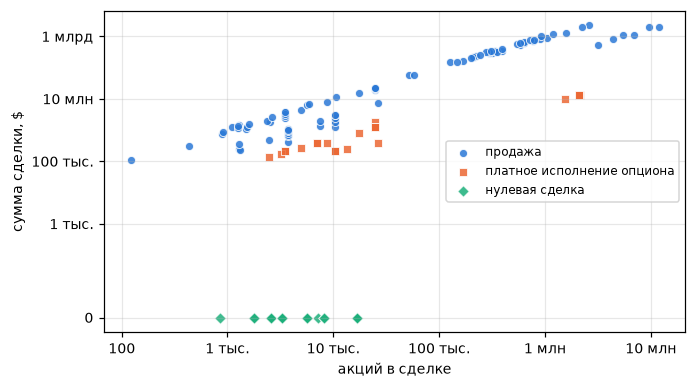

In [4]:
DOLLAR_TICKS = {0: "0", 1e3: "1 тыс.", 1e5: "100 тыс.", 1e7: "10 млн", 1e9: "1 млрд"}
SHARE_TICKS = {
    1e2: "100",
    1e3: "1 тыс.",
    1e4: "10 тыс.",
    1e5: "100 тыс.",
    1e6: "1 млн",
    1e7: "10 млн",
}


def draw_groups(ax, x, y):
    for name, (color, marker) in GROUPS.items():
        members = group == name
        ax.scatter(
            x[members],
            y[members],
            color=color,
            marker=marker,
            s=28,
            alpha=0.85,
            edgecolors="white",
            linewidths=0.6,
            label=name,
        )


fig, ax = plt.subplots(figsize=(6.4, 3.6))
draw_groups(ax, X_tesla["log_shares"], np.log1p(value))
ax.set_xticks(np.log1p(list(SHARE_TICKS)), list(SHARE_TICKS.values()))
ax.set_yticks(np.log1p(list(DOLLAR_TICKS)), list(DOLLAR_TICKS.values()))
ax.set_xlabel("акций в сделке")
ax.set_ylabel("сумма сделки, $")
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="center right")
fig.tight_layout()
plt.show()

Продажи легли почти на прямую: если акций в десять раз больше, то и сумма примерно в десять раз
больше. Сумма сделки равна цене акции, умноженной на число акций, а в логарифмической шкале —
сумме:

$$\ln(\text{сумма}) = \ln(\text{цена}) + \ln(\text{акций}) .$$

Исполнения опционов лежат ниже продаж: цена исполнения от 6 до 74 \$ за акцию при рыночной цене от
109 до 1171 \$. Внизу отдельной строкой стоят 18 сделок с нулевой суммой. Все они — исполнения
опционов 5-го числа последнего месяца квартала, и совершали их три руководителя: главный бухгалтер,
финансовый директор и вице-президент. Скорее всего, это ежеквартальное начисление акций в счёт
вознаграждения, за которое ничего не платят.

Поэтому модель предсказывает логарифм суммы:

$$y = \ln(1 + \text{сумма}) .$$

Единица добавлена из-за нулевых сумм, логарифм нуля не определён. Без логарифма квадраты отклонений
на продажах Маска в сотни миллионов долларов перевесили бы все остальные сделки. После приведения
к логарифмической шкале важна ошибка в разах: промах вдвое весит одинаково у сделки на 1 млн \$ и
у сделки на 1 млрд \$.

## 2. Линейная регрессия

Линейная регрессия предсказывает цель взвешенной суммой признаков:

$$\hat{y} = w_0 + w_1 x_1 + \dots + w_m x_m ,$$

где $w_0$ — свободный член, $w_j$ — вес признака $x_j$. Вес показывает, на сколько изменится
прогноз, если увеличить $x_j$ на единицу и не трогать остальные признаки. Цель у нас — логарифм
суммы, поэтому прибавка $w_j$ к прогнозу означает, что сумма умножается на $e^{w_j}$.

Веса подбираются методом наименьших квадратов, т. е. берутся такие, при которых сумма квадратов
ошибок на обучающей выборке наименьшая

$$\sum_{i=1}^{n} (y_i - \hat{y}_i)^2 \to \min .$$

Остаток $y_i - \hat{y}_i$ — ошибка модели на одной сделке. Квадрат сильнее наказывает большие
ошибки, поэтому модели выгоднее понемногу ошибиться везде, чем сильно в одной точке. Для линейной
регрессии такие веса находятся точно, решением системы линейных уравнений.

### Категориальные признаки

Тип сделки и должность — строки, и умножить их на вес нельзя. Их кодируют one-hot: для каждого
значения заводится столбец, в котором стоит 1, если у сделки это значение, и 0 иначе. Из
`transaction` получаются столбцы `transaction_Sale` и `transaction_Option Exercise`.

Оба столбца оставить нельзя. В каждой строке их сумма равна 1 — так же, как у столбца из единиц, на
который умножается свободный член. Тогда разные веса дают одинаковые прогнозы:

- $w_0 = 10,\ w_{\text{Sale}} = 3,\ w_{\text{Option}} = 0$ дают 13 для продажи и 10 для опциона;
- $w_0 = 7,\ w_{\text{Sale}} = 6,\ w_{\text{Option}} = 3$ дают те же 13 и 10.

Метод наименьших квадратов не может выбрать между ними, и веса теряют смысл. Это
мультиколлинеарность, как у копий признаков в ЛР 2, только зависимость здесь точная. Поэтому у
каждого категориального признака первое по алфавиту значение удаляется и становится точкой отсчёта:
у `transaction` это исполнение опциона, у `relationship` — генеральный директор. Вес
`transaction_Sale` показывает, насколько продажа отличается от исполнения опциона, если остальные
признаки одинаковые.

### Масштабирование

Числовые признаки стандартизируются: из каждого вычитается среднее, и результат делится на
стандартное отклонение, $z = (x - \bar{x}) / \sigma$. На прогноз линейной регрессии это не влияет:
если признак разделить на $\sigma$, его вес умножится на $\sigma$. Зато веса числовых признаков
становятся сравнимыми: каждый показывает, как меняется прогноз, если признак вырос на одно
стандартное отклонение.

Кодирование, масштабирование и регрессия собраны в один конвейер (пайплайн). Конвейер запоминает
категории и средние по обучающей выборке и применяет их к новым сделкам, поэтому проверочные сделки
в подготовке признаков не участвуют. Логарифм цели тоже берётся внутри модели, а прогноз
переводится обратно в доллары.

На обучение отведено 75% сделок, на проверку — 25%, т. е. 39 сделок. Разбиение стратифицировано по
типу сделки: доля продаж в обеих частях почти одинаковая. Ниже четыре обучающие сделки после
подготовки признаков.

In [5]:
X_train, X_test, value_train, value_test = train_test_split(
    X_tesla, value, test_size=TEST_SIZE, stratify=X_tesla["transaction"], random_state=RANDOM_STATE
)
model = build_pipeline(LinearRegression(), CATEGORICAL, NUMERIC).fit(X_train, value_train)
preprocess = model.regressor_["preprocess"]

pd.DataFrame(
    preprocess.transform(X_train.head(4)),
    columns=preprocess.get_feature_names_out(),
    index=X_train.head(4).index,
).round(2).T

,100,26,62,93
transaction_Sale,1.00,1.00,0.00,0.00
relationship_Chief Accounting Officer,0.00,0.00,0.00,0.00
relationship_Chief Financial Officer,0.00,0.00,0.00,0.00
relationship_Director,1.00,0.00,0.00,0.00
relationship_SVP Powertrain and Energy Eng.,0.00,1.00,1.00,1.00
log_shares,-0.03,-0.36,-1.31,-1.03
month,-1.50,0.81,-0.47,-1.24
year,0.68,0.68,0.68,0.68


Сделка 100 — продажа члена совета директоров, поэтому у неё единицы в `transaction_Sale` и
`relationship_Director`. Сделки 62 и 93 — исполнения опционов вице-президентом, и в
`transaction_Sale` у них ноль. Генеральному директору соответствуют нули во всех столбцах
`relationship`. У `year` всего два значения, 2021 и 2022, и после стандартизации 2022 год стал
числом 0.68.

## 3. Оценка качества

Качество оценивается тремя метриками. Коэффициент детерминации

$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2} ,$$

где $\hat{y}_i$ — прогноз модели, $\bar{y}$ — среднее значение цели. В числителе стоит квадрат
ошибки модели, в знаменателе — квадрат ошибки константы, которая всегда предсказывает среднее.
При $R^2 = 0$ модель не лучше среднего, при $R^2 = 1$ попадает точно, отрицательный $R^2$ значит,
что модель хуже константы.

Средняя абсолютная ошибка (MAE) и корень из средней квадратичной ошибки (RMSE):

$$\mathrm{MAE} = \frac{1}{n} \sum_{i=1}^{n} \lvert y_i - \hat{y}_i \rvert , \qquad
\mathrm{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2} .$$

Обе измеряются в единицах цели. RMSE не меньше MAE, и разница между ними растёт, если среди ошибок
есть крупные: четыре ошибки по 1 дают MAE = RMSE = 1, а ошибки 0, 0, 0 и 4 дают ту же MAE = 1, но
RMSE = 2.

Разность логарифмов равна логарифму отношения, поэтому MAE в логарифмах переводится в разы: в
среднем прогноз отличается от факта в $e^{\mathrm{MAE}}$ раз.

Кроме отложенной выборки модель проверена кросс-валидацией: сделки делятся на 10 частей, модель
10 раз обучается на девяти частях и проверяется на оставшейся. Каждая сделка ровно один раз
попадает в проверку, и метрики считаются по всем 156 прогнозам сразу.

In [6]:
folds = KFold(FOLDS, shuffle=True, random_state=RANDOM_STATE)
holdout = model.predict(X_test)
predicted = pd.Series(
    cross_val_predict(
        build_pipeline(LinearRegression(), CATEGORICAL, NUMERIC), X_tesla, value, cv=folds
    ),
    index=tesla.index,
)


def log_report(actual, prediction):
    report = regression_report(np.log1p(actual), np.log1p(prediction))
    return {**report, "во сколько раз": np.exp(report["MAE"])}


pd.DataFrame(
    {
        f"отложенная выборка, {len(X_test)}": log_report(value_test, holdout),
        f"кросс-валидация, {FOLDS} частей": log_report(value, predicted),
    }
).round(3)

,"отложенная выборка, 39","кросс-валидация, 10 частей"
R²,0.668,0.685
MAE,2.401,2.271
RMSE,3.271,3.259
во сколько раз,11.031,9.688


На отложенной выборке $R^2 = 0.668$, на кросс-валидации — 0.685, оценки близки. Модель объясняет
около двух третей разброса логарифма суммы. При этом средняя ошибка большая: MAE на
кросс-валидации 2.27, т. е. в среднем прогноз отличается от факта почти в 10 раз. RMSE заметно
больше MAE, значит, среди ошибок есть крупные.

Ниже те же метрики в долларах: прогноз переведён обратно из логарифма.

In [7]:
def dollar_report(actual, prediction):
    report = regression_report(actual, prediction)
    return {
        "R²": round(report["R²"], 3),
        "MAE, млн $": report["MAE"] / 1e6,
        "RMSE, млн $": report["RMSE"] / 1e6,
    }


musk = tesla["insider"] == "Musk Elon"
dollar_error = (value - predicted).abs()
pd.DataFrame(
    {
        f"отложенная выборка, {len(X_test)}": dollar_report(value_test, holdout),
        f"кросс-валидация, {FOLDS} частей": dollar_report(value, predicted),
    }
).round(1)

,"отложенная выборка, 39","кросс-валидация, 10 частей"
R²,-0.2,0.4
"MAE, млн $",121.0,99.8
"RMSE, млн $",346.2,322.2


В долларах результат хуже: на кросс-валидации $R^2 = 0.40$, а на отложенной выборке $R^2 = -0.20$,
т. е. модель хуже константы. MAE — около 100 млн \$, хотя медианная сделка стоит 2 млн \$.

In [8]:
make_table(
    {
        "сделок Маска": int(musk.sum()),
        "доля Маска в сумме всех сделок": f"{value[musk].sum() / value.sum():.1%}",
        "доля Маска в ошибке, $": f"{dollar_error[musk].sum() / dollar_error.sum():.1%}",
        "медианная ошибка, $": f"{dollar_error.median():,.0f}",
    },
    column="кросс-валидация",
)

,кросс-валидация
,
сделок Маска,53
доля Маска в сумме всех сделок,99.2%
"доля Маска в ошибке, $",90.7%
"медианная ошибка, $","1,508,148"


На Маска приходится треть сделок и 99.2% общей суммы: на остальных инсайдеров — 220 млн \$ из
28.4 млрд \$. Поэтому и ошибка в долларах на 91% состоит из ошибок на его сделках. Если модель
ошиблась на 20% на продаже за 2.28 млрд \$, это 456 млн \$ — вдвое больше, чем все сделки
остальных инсайдеров вместе.

Метрики в долларах определяются несколькими крупнейшими продажами Маска, а медианная ошибка — всего
1.5 млн \$. От того, какие из этих продаж попали в 39 проверочных сделок, зависит и $R^2$ на
отложенной выборке. Поэтому дальше качество оценивается в логарифмической шкале.

## 4. Остатки модели

Метод наименьших квадратов можно использовать, если остатки разбросаны хаотично: в среднем равны
нулю и не зависят от прогноза. Если в остатках видна закономерность, скорее всего выбрана
неправильная модель.

Ниже два графика по прогнозам кросс-валидации. На обоих по горизонтали
отложен прогноз логарифма суммы. На левом по вертикали — факт, и точный прогноз лежит на
диагонали: точки выше неё модель недооценила, ниже — переоценила. На правом по вертикали — остаток,
т. е. факт минус прогноз, и точный прогноз лежит на линии нуля. Крупные ошибки, из-за которых RMSE
больше MAE, — это точки, далёкие от этих линий.

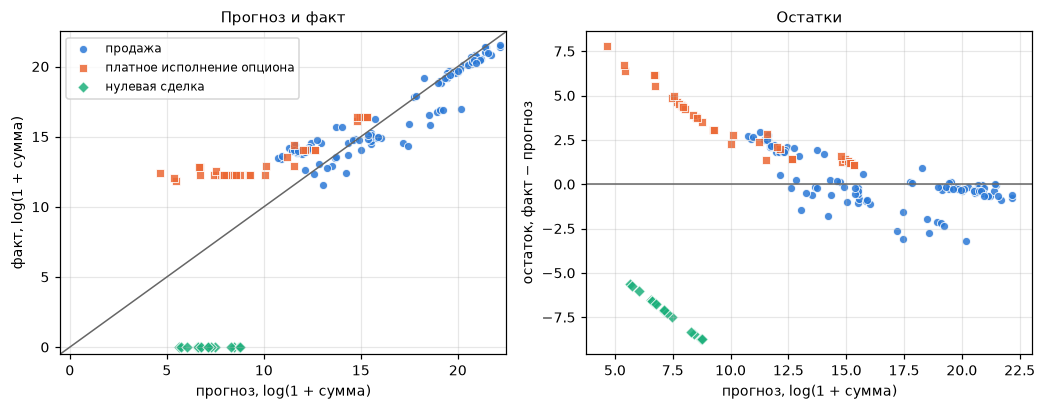

In [9]:
log_value = np.log1p(value)
log_predicted = np.log1p(predicted)
residual = log_value - log_predicted

fig, (ax_fit, ax_residual) = plt.subplots(1, 2, figsize=(9.6, 3.8))
draw_groups(ax_fit, log_predicted, log_value)
limits = (-0.5, 22.5)
ax_fit.plot(limits, limits, color="0.4", linewidth=1)
ax_fit.set_xlim(limits)
ax_fit.set_ylim(limits)
ax_fit.set_xlabel("прогноз, log(1 + сумма)")
ax_fit.set_ylabel("факт, log(1 + сумма)")
ax_fit.set_title("Прогноз и факт")

draw_groups(ax_residual, log_predicted, residual)
ax_residual.axhline(0, color="0.4", linewidth=1)
ax_residual.set_xlabel("прогноз, log(1 + сумма)")
ax_residual.set_ylabel("остаток, факт − прогноз")
ax_residual.set_title("Остатки")
for ax in (ax_fit, ax_residual):
    ax.grid(alpha=0.3)
ax_fit.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

Остатки не хаотичны, сделки разошлись на три группы:

- продажи лежат вдоль диагонали, крупные — ближе к ней;
- платные исполнения опционов почти все выше диагонали, т. е. модель их недооценивает;
- нулевые сделки ниже всех: факт 0, а прогноз от 5.6 до 8.8, т. е. от 270 до 6.3 тыс. \$.

Справа группы вытянуты в наклонные полосы. У нулевых сделок факт всегда 0, поэтому остаток равен
прогнозу с минусом, и все точки лежат на одной прямой. Платные опционы образуют такую же полосу: 15
из них — ежемесячные исполнения опционов Эндрю Баглино почти на одну и ту же сумму, 219.5 тыс. \$,
а прогнозы для них разные. Ниже вклад каждой группы в сумму квадратов остатков.

In [10]:
squared = residual**2
pd.DataFrame(
    {
        "сделок": group.value_counts(),
        "средний остаток": residual.groupby(group).mean(),
        "доля квадрата ошибки": squared.groupby(group).sum() / squared.sum(),
    }
).loc[list(GROUPS)].round(3)

,сделок,средний остаток,доля квадрата ошибки
продажа,99,0.037,0.112
платное исполнение опциона,39,3.267,0.333
нулевая сделка,18,-7.092,0.555


Нулевые сделки — это 12% набора, но на них приходится 55.5% суммы квадратов остатков, и ещё
33.3% — на платные опционы. Модель переоценивает нулевые сделки в среднем на 7.09 и недооценивает
платные опционы на 3.27, т. е. в $e^{3.27} \approx 26$ раз.

Нулевые и платные опционы получают один общий вес «исполнение опциона». Остальные признаки их не
различают: у тех же руководителей и в те же месяцы есть и платные исполнения. Метод наименьших
квадратов ставит уровень опционов между двумя группами, и модель ошибается в обеих.

Ниже веса модели, обученной на 117 сделках. Столбец «вес» — то, что выучила модель, у числовых
признаков он относится к одному стандартному отклонению. Столбец «на единицу признака» — вес,
делённый на $\sigma$ признака, а «множитель суммы» $e^{w}$ показывает, во сколько раз меняется
сумма.

In [11]:
def coefficients(fitted):
    pipeline = fitted.regressor_
    weights = pd.Series(
        pipeline["regressor"].coef_, index=pipeline["preprocess"].get_feature_names_out()
    )
    number = pipeline["preprocess"].named_transformers_["number"]
    scale = pd.Series(number.scale_, index=number.feature_names_in_)
    return weights / scale.reindex(weights.index, fill_value=1.0)


weights = coefficients(model)
pd.DataFrame(
    {
        "вес": model.regressor_["regressor"].coef_,
        "на единицу признака": weights,
        "множитель суммы": np.exp(weights),
    },
    index=weights.index,
).round(3)

,вес,на единицу признака,множитель суммы
transaction_Sale,7.548,7.548,1896.897
relationship_Chief Accounting Officer,1.233,1.233,3.431
relationship_Chief Financial Officer,0.662,0.662,1.938
relationship_Director,4.476,4.476,87.867
relationship_SVP Powertrain and Energy Eng.,3.072,3.072,21.584
log_shares,4.029,1.534,4.638
month,-0.896,-0.230,0.794
year,-1.219,-2.621,0.073


Из числовых признаков самый большой вес на стандартное отклонение у `log_shares`, 4.03, у года и
месяца −1.22 и −0.90. Сильнее всего на сумму влияет число акций.

Веса на единицу признака:

- `transaction_Sale` — 7.55: продажа в $e^{7.55} \approx 1900$ раз дороже исполнения опциона, хотя
  рыночная цена акции выше цены исполнения в среднем в 24 раза. Разницу добавили нулевые сделки.
- Веса должностей отсчитываются от генерального директора. Больше всего вес у членов совета
  директоров, 4.48: при тех же признаках их сделка в 88 раз дороже сделки Маска.
- `log_shares` — 1.53: если акций вдвое больше, сумма больше в $2^{1.53} \approx 2.9$ раза, хотя
  при той же цене акции была бы больше ровно вдвое.
- `year` — −2.62: сделка 2022 года в 14 раз меньше такой же сделки 2021 года. Цена акции за период
  действительно упала, но не в 14 раз.

Знаки весов объяснимы, но сами веса слишком большие, скорее всего из-за нулевых сделок.

## 5. Применимость линейной регрессии

Чтобы проверить, что модель портят именно нулевые сделки, она обучена заново без них. Ниже обе
модели сравниваются кросс-валидацией на одних и тех же 138 сделках с ненулевой суммой.

In [12]:
nonzero_model = build_pipeline(LinearRegression(), CATEGORICAL, NUMERIC).fit(
    X_train[value_train > 0], value_train[value_train > 0]
)
nonzero = pd.Series(
    cross_val_predict(
        build_pipeline(LinearRegression(), CATEGORICAL, NUMERIC),
        X_tesla[~zero],
        value[~zero],
        cv=folds,
    ),
    index=X_tesla.index[~zero],
)

pd.DataFrame(
    {
        "все сделки": log_report(value[~zero], predicted[~zero]),
        "без нулевых сделок": log_report(value[~zero], nonzero),
    }
).round(3)

,все сделки,без нулевых сделок
R²,0.403,0.951
MAE,1.642,0.515
RMSE,2.310,0.662
во сколько раз,5.166,1.673


Без нулевых сделок $R^2$ вырос с 0.403 до 0.951, а средняя ошибка уменьшилась с 5.2 до 1.7 раза.
$R^2$ первой модели здесь меньше, чем 0.685 в разделе 3: среднее, с которым его сравнивают, теперь
считается только по ненулевым сделкам. Значит, заметная часть от 0.685 — это разница между нулевыми
и остальными сделками, которую модель хотя бы частично уловила.

Ниже веса модели, обученной на тех же 117 сделках, но без нулевых, рядом с прежними, на единицу
признака.

In [13]:
pd.DataFrame({"все сделки": weights, "без нулевых сделок": coefficients(nonzero_model)}).round(3)

,все сделки,без нулевых сделок
transaction_Sale,7.548,3.261
relationship_Chief Accounting Officer,1.233,-0.880
relationship_Chief Financial Officer,0.662,-1.512
relationship_Director,4.476,-0.279
relationship_SVP Powertrain and Energy Eng.,3.072,-0.900
log_shares,1.534,0.776
month,-0.230,-0.090
year,-2.621,-0.701


Веса стали правдоподобнее:

- продажа теперь дороже исполнения опциона в $e^{3.26} \approx 26$ раз — примерно во столько же
  раз рыночная цена акции выше цены исполнения;
- вес `log_shares` 0.78: если акций вдвое больше, сумма больше в 1.7 раза. Скорее всего, его
  занижают опционы Маска на миллионы акций по 6.24 \$, из-за них же веса остальных должностей
  стали отрицательными;
- сделка 2022 года вдвое меньше сделки 2021 года ($e^{-0.70} \approx 0.5$). Раньше вес года
  частично объяснял нулевые сделки: 15 из 18 пришлись на 2022 год.

Сумма сделки — произведение цены на число акций, а в логарифмической шкале — сумма, поэтому
линейная регрессия хорошо описывает платные сделки. У нулевых сделок сумма 0 при любом числе акций,
и сложением весов этого не описать. Признаков, которые отличали бы их от платных, в задаче тоже
нет.

### Оценка метода

Для платных сделок линейная регрессия в логарифмах подходит: $R^2 = 0.951$, прогноз в среднем
отличается от факта в 1.7 раза, а веса объясняются ценой акции и её падением за период. При этом на
всём наборе она подходит только частично: нулевые сделки нужно отделять до регрессии, иначе они
портят веса и прогнозы для остальных сделок.

## 6. Почему в признаках нет цены акции

Если добавить в признаки логарифм цены `log_cost`, у модели будут оба слагаемых
$\ln(\text{сумма}) = \ln(\text{цена}) + \ln(\text{акций})$. Ниже $R^2$ кросс-валидации с ценой и
без неё, на всех сделках и без нулевых.

In [14]:
X_leak = X_tesla.assign(log_cost=np.log1p(tesla["cost"]))
leak_pipeline = build_pipeline(LinearRegression(), CATEGORICAL, [*NUMERIC, "log_cost"])
leak = cross_val_predict(leak_pipeline, X_leak, value, cv=folds)
leak_nonzero = cross_val_predict(leak_pipeline, X_leak[~zero], value[~zero], cv=folds)


def log_r2(actual, prediction):
    return regression_report(np.log1p(actual), np.log1p(prediction))["R²"]


pd.DataFrame(
    {
        "без цены": {
            "все сделки": log_r2(value, predicted),
            "без нулевых сделок": log_r2(value[~zero], nonzero),
        },
        "с ценой": {
            "все сделки": log_r2(value, leak),
            "без нулевых сделок": log_r2(value[~zero], leak_nonzero),
        },
    }
).round(5)

,без цены,с ценой
все сделки,0.68534,0.94458
без нулевых сделок,0.95092,0.99997


С ценой $R^2$ на всех сделках вырос с 0.685 до 0.945, а без нулевых сделок — с 0.951 до 0.99997.
Ниже веса модели с ценой, обученной без нулевых сделок.

In [15]:
leak_weights = coefficients(leak_pipeline.fit(X_leak[~zero], value[~zero]))
leak_weights[["log_cost", "log_shares"]].round(3).to_frame("на единицу признака")

,на единицу признака
log_cost,1.032
log_shares,1.002


Веса `log_cost` и `log_shares` равны 1.03 и 1.00: модель восстановила определение суммы,
$\ln(\text{сумма}) = \ln(\text{цена}) + \ln(\text{акций})$. Это утечка целевой переменной: если
цена и число акций известны, сумма считается умножением, и модель не нужна. На всех сделках ошибка
остаётся из-за нулевых сделок, для них это равенство не выполняется.

## Выводы

1. Сформулирована задача регрессии: предсказать сумму сделки инсайдера Tesla по типу сделки,
   должности, числу акций, месяцу и году. Сумма и число акций приведены к логарифмической шкале,
   категориальные признаки закодированы one-hot, числовые стандартизированы.
2. Линейная регрессия объясняет около двух третей разброса логарифма суммы: $R^2 = 0.668$ на
   отложенной выборке и 0.685 на кросс-валидации. В среднем прогноз отличается от факта почти в
   10 раз.
3. В долларах $R^2 = 0.40$ на кросс-валидации и −0.20 на отложенной выборке. На сделки Маска
   приходится 99.2% общей суммы и 91% ошибки в долларах, поэтому качество оценивалось в
   логарифмической шкале.
4. Остатки не хаотичны. 18 нулевых сделок дают 55.5% суммы квадратов остатков: у них общий вес с
   платными исполнениями опционов, и модель ошибается в обеих группах.
5. Без нулевых сделок $R^2 = 0.951$, а прогноз в среднем отличается от факта в 1.7 раза. Для
   платных сделок линейная регрессия в логарифмах подходит, т. к. логарифм превращает произведение
   цены и числа акций в сумму. Нулевые сделки сложением признаков не описать, на всём наборе модель
   подходит только частично.
6. Если добавить цену акции, $R^2$ доходит до 0.99997: модель восстанавливает определение суммы.
   Поэтому цена в признаки не входит.

## Контрольные вопросы

**1. Какую задачу для решения вы сформулировали?**

Задача регрессии: по типу сделки, должности инсайдера, числу акций, месяцу и году предсказать сумму
сделки инсайдера Tesla. Это обучение с учителем: сумма каждой сделки в наборе известна, и модель
учится восстанавливать её по признакам. Модель предсказывает логарифм суммы, т. к. суммы
различаются на несколько порядков. Цена акции в признаки не входит: вместе с числом акций она даёт
сумму без всякой модели.

**2. Как вы оценили качество решения?**

Метриками $R^2$, MAE и RMSE на отложенной выборке из 39 сделок и кросс-валидацией на 10 частях, в
логарифмической шкале и в долларах. Основной оценкой выбран $R^2$ в логарифмической шкале: в
долларах метрики определяются несколькими продажами Маска.

Кроме того, проверены остатки модели. По ним найдена группа нулевых сделок, которую модель описать
не может, и это подтверждено обучением модели без них.

**3. Расскажите подробнее об используемой вами модели.**

Линейная регрессия предсказывает цель взвешенной суммой признаков. Веса подбираются методом
наименьших квадратов, решение единственно и находится аналитически. Вес показывает, на сколько
изменится прогноз, если признак вырастет на единицу, а остальные не изменятся. Категориальные
признаки кодируются one-hot с удалением одного значения, иначе возникает мультиколлинеарность и
веса неоднозначны. Модель быстро обучается и легко объясняется весами, но умеет только складывать
вклады признаков: правило «если цена нулевая, то и сумма нулевая» ей недоступно. Метод наименьших
квадратов чувствителен к выбросам, т. к. ошибки возводятся в квадрат, поэтому цель с разбросом на
несколько порядков нужно логарифмировать.